# OrbitML

Un TLE (Two-Line Element) est une orbite approximative. Propagé avec le modèle SGP4, il prédit la position d'un satellite avec une erreur de l'ordre du kilomètre, et cette erreur grandit. Or cette erreur n'est pas du bruit : elle a une structure. Peng & Bai (2018) proposent d'entrainer un modèle à trouver cette erreur, puis de l'ajouter à la prédiction SGP4.

Pour mesurer l'erreur de SGP4, il faut connaître la vraie position du satellite. On utilise les orbites précises (POE) de Sentinel-6A, calculées par le CNES, avec une précision de l'ordre du centimètre. On a choisi Sentinel-6A parce qu'il fait très peu de manœuvres (4 en 2024).

## Étape 1 : la vérité

Les orbites précises de Sentinel-6A sont dans `data/sp3/s6a/`, au format SP3, un format texte standard. Chaque fichier est compressé en `.Z`. Le module `gzip` de Python ne sait pas le lire, mais la commande `gzip -dc` le décompresse très bien.

Voici à quoi ressemble un fichier une fois décompressé :

```
#cV2023 12 13  3 21  0.00000000   14308 ORBIT ITRF  FIT CNES      <- date de début, 14308 états, repère ITRF
## 2292 271260.00000000    60.00000000 ...                        <- semaine GPS, pas de temps = 60 s
%c L  cc TAI ...                                                  <- échelle de temps : TAI
...
*  2023 12 13  3 21  0.00000000                                   <- une date
PL40  3468.7606188  -817.1050730 -6844.2029489 999999.999999      <- position x, y, z en km
VL40-15613.8151346 65922.4868150-15775.4078392 999999.999999      <- vitesse vx, vy, vz en dm/s
*  2023 12 13  3 22  0.00000000
...
```

Quelques remarques :

- Le repère est l'ITRF, un repère qui tourne avec la Terre. SGP4, lui, donne des positions dans TEME. Il faudra convertir l'un dans l'autre
- Les dates sont en TAI, pas en UTC.
- Les vitesses sont en dm/s. On les divise par 10⁴ pour avoir des km/s.
- Un fichier couvre environ 10 jours, avec un état par minute.

In [1]:
import copy
import subprocess
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.coordinates import ITRS, TEME, CartesianRepresentation
from astropy.time import Time
from sgp4.api import Satrec
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import MinMaxScaler

On lit un seul fichier pour commencer. Pour chaque date (ligne `*`), on garde la position (ligne `P`) et la vitesse (ligne `V`).

In [2]:
path = Path("data/sp3/s6a/ssas6a30.b24001.e24011.DG_.sp3.001.Z")
lines = subprocess.run(["gzip", "-dc", path], capture_output=True, text=True, check=True).stdout.splitlines()

dates, r, v = [], [], []
for line in lines:
    if line.startswith("*"):
        # "*  2023 12 13  3 21  0.00000000" -> année, mois, jour, heure, minute, seconde
        dates.append([float(x) for x in line[1:].split()])
    elif line.startswith("P"):
        r.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])
    elif line.startswith("V"):
        v.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])

dates = np.array(dates)
year, month, day, hour, minute = dates[:, :5].astype(int).T  # astropy veut des entiers ici
time = Time(
    {"year": year, "month": month, "day": day, "hour": hour, "minute": minute, "second": dates[:, 5]},
    format="ymdhms", scale="tai",
)
r = np.array(r)          # km, ITRF
v = np.array(v) / 1e4    # dm/s -> km/s, ITRF

print(len(time), "états, de", time[0].utc.iso, "à", time[-1].utc.iso, "UTC")
print("pas de temps :", np.unique(np.diff(time.unix)), "s")
print("r :", r.shape, " v :", v.shape)

14308 états, de 2024-01-01 23:17:23.000 à 2024-01-11 21:44:23.000 UTC
pas de temps : [60.] s
r : (14308, 3)  v : (14308, 3)


La distance au centre de la Terre moins le rayon terrestre (6378 km à l'équateur) doit redonner l'altitude annoncée de Sentinel-6A, environ 1336 km.

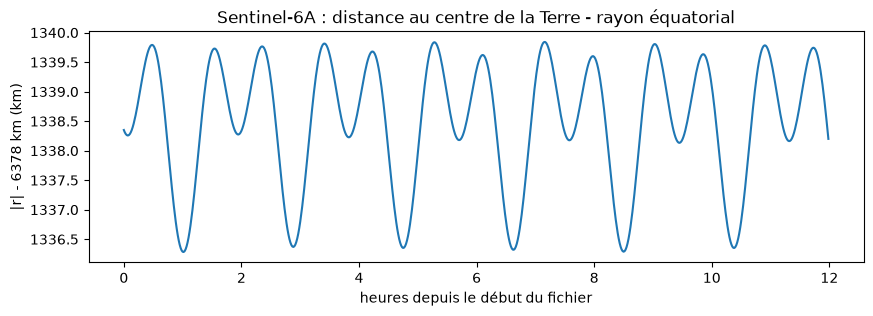

|r| - 6378 km : de 1336.2 à 1339.9 km sur tout le fichier


In [3]:
EARTH_RADIUS = 6378.137  # km, rayon équatorial

distance = np.linalg.norm(r, axis=1)
hours = (time - time[0]).to_value("hour")
first = hours < 12

plt.figure(figsize=(10, 3))
plt.plot(hours[first], distance[first] - EARTH_RADIUS)
plt.xlabel("heures depuis le début du fichier")
plt.ylabel("|r| - 6378 km (km)")
plt.title("Sentinel-6A : distance au centre de la Terre - rayon équatorial")
plt.show()

print(f"|r| - 6378 km : de {distance.min() - EARTH_RADIUS:.1f} à {distance.max() - EARTH_RADIUS:.1f} km sur tout le fichier")

On retrouve environ 1338 km, et la distance au centre ne varie que de ±2 km : l'orbite est presque circulaire.

On trace les 6 premières heures, soit environ 3 révolutions.

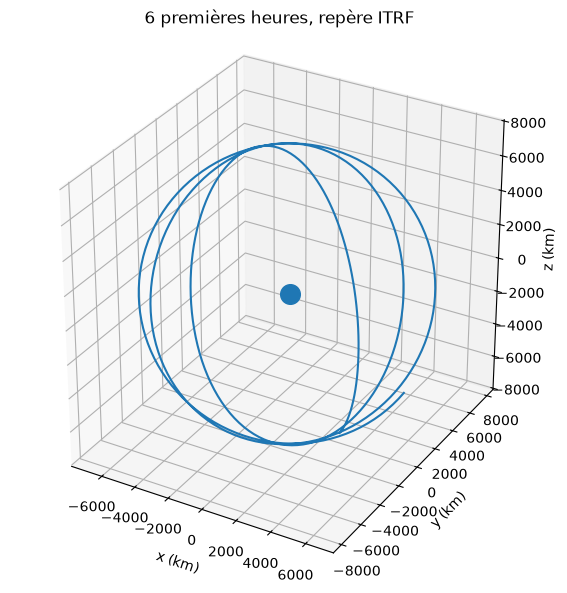

In [4]:
first = hours < 6

ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.plot(*r[first].T)
ax.scatter(0, 0, 0, color="tab:blue", s=200)  # la Terre, pas à l'échelle
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")
ax.set_aspect("equal")
ax.set_title("6 premières heures, repère ITRF")
plt.show()

L'orbite ne se referme pas : chaque révolution est décalée par rapport à la précédente. Ce n'est pas le satellite qui dérive, c'est le repère : l'ITRF tourne avec la Terre, d'environ 28° pendant une révolution.

## Étape 2 : SGP4

Les TLE de Sentinel-6A sont dans `data/tle/`. On n'en a qu'à partir de 2024, c'est pour ça qu'on lit le fichier SP3 du 1er janvier 2024 à l'étape 1. Un TLE tient sur deux lignes :

```
1 46984U 20086A   24001.60261332 -.00000054  00000-0  31477-4 0  9993     <- date du TLE : 2024, jour 1.6026
2 46984  66.0389 199.3442 0007637 269.6041  90.4099 12.80929714145361     <- inclinaison, nœud, excentricité 0.0007637, ..., 12.8 révolutions par jour
```

Pour l'instant, on prend juste le premier TLE du fichier.

In [5]:
tle = Path("data/tle/46984_2024-01-01_2025-01-02.tle").read_text().splitlines()
satellite = Satrec.twoline2rv(tle[0], tle[1])
tle_date = Time(satellite.jdsatepoch, satellite.jdsatepochF, format="jd", scale="utc")

print("date du TLE :", tle_date.iso, "UTC")

date du TLE : 2024-01-01 14:27:45.791 UTC


SGP4 donne la position en TEME, en km, aux dates qu'on lui demande (en UTC). On lui demande les dates du SP3, à partir de la date du TLE.

In [6]:
after = time >= tle_date
error, r_sgp4, v_sgp4 = satellite.sgp4_array(time[after].utc.jd1, time[after].utc.jd2)

print("codes d'erreur :", np.unique(error))  # 0 = tout va bien
print("r_sgp4 :", r_sgp4.shape)

codes d'erreur : [0]
r_sgp4 : (14308, 3)


Pour comparer, on passe la vérité de l'ITRF au TEME avec astropy.

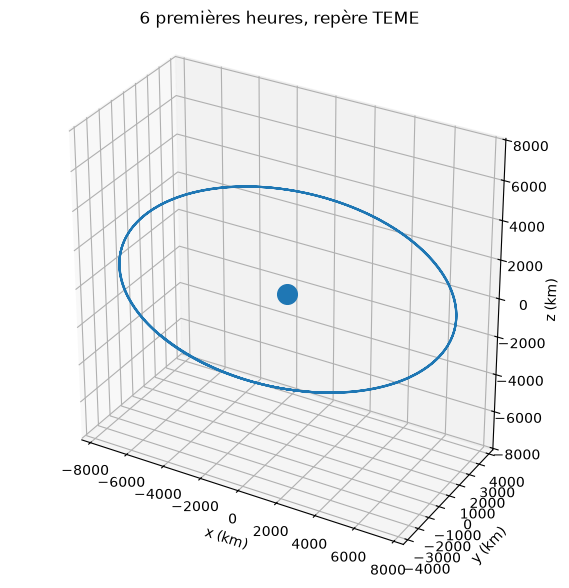

In [7]:
itrs = ITRS(CartesianRepresentation(r[after].T * u.km), obstime=time[after])
r_true = itrs.transform_to(TEME(obstime=time[after])).cartesian.xyz.to_value(u.km).T

ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.plot(*r_true[:360].T)  # 360 états de 60 s = 6 h
ax.scatter(0, 0, 0, color="tab:blue", s=200)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")
ax.set_aspect("equal")
ax.set_title("6 premières heures, repère TEME")
plt.show()

Cette fois, l'orbite se referme : TEME ne tourne pas avec la Terre. Les deux positions sont maintenant dans le même repère, on peut regarder la distance entre elles.

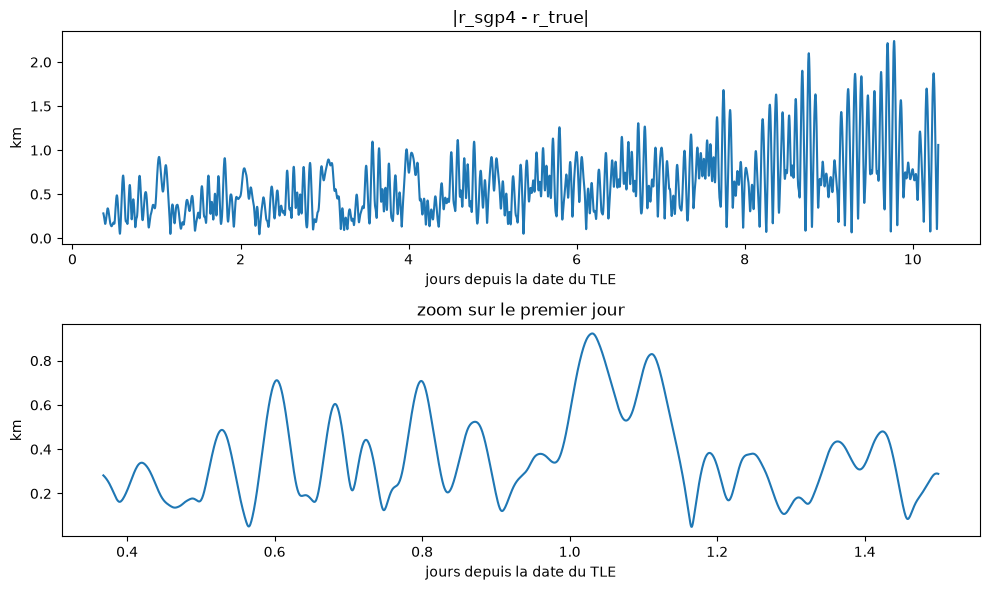

In [8]:
days = (time[after] - tle_date).to_value("day")
distance = np.linalg.norm(r_sgp4 - r_true, axis=1)
first = days < 1.5

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6))
top.plot(days, distance)
top.set_title("|r_sgp4 - r_true|")
bottom.plot(days[first], distance[first])
bottom.set_title("zoom sur le premier jour")
for ax in (top, bottom):
    ax.set_xlabel("jours depuis la date du TLE")
    ax.set_ylabel("km")
fig.tight_layout()
plt.show()

L'erreur part d'environ 300 m et monte jusqu'à environ 2 km au bout de 10 jours. Elle n'est pas aléatoire : elle oscille au rythme des révolutions et son amplitude grandit. C'est cette structure qu'on voudra apprendre.

## Étape 3 : l'erreur dans le repère RSW

La norme ne dit pas dans quelle direction SGP4 se trompe. On projette donc l'erreur $e = r_{true} - r_{sgp4}$ sur trois directions liées au satellite. C'est la convention de Peng & Bai : $e$ est ce qu'il faut ajouter à SGP4 pour retrouver la vérité.

- R (radial) : de la Terre vers le satellite, $R = \dfrac{r}{|r|}$
- W (perpendiculaire au plan de l'orbite) : $W = \dfrac{r \times v}{|r \times v|}$
- S (le long de la trajectoire) : $S = W \times R$, presque dans le sens de la vitesse

On construit ce repère à partir de la position et de la vitesse SGP4, pas de la "vérité". Le but est de corriger une prédiction, et au moment de prédire on ne connaît que SGP4.

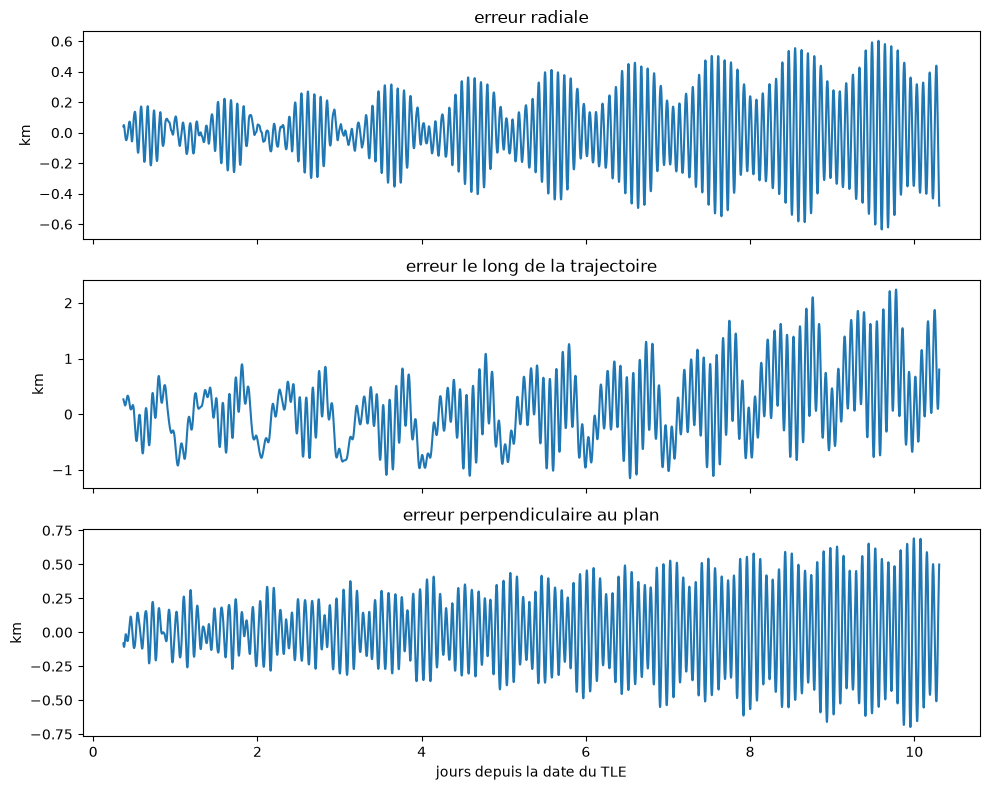

R : de -0.63 à 0.60 km
S : de -1.15 à 2.24 km
W : de -0.70 à 0.69 km


In [9]:
e = r_true - r_sgp4

R = r_sgp4 / np.linalg.norm(r_sgp4, axis=1, keepdims=True)
W = np.cross(r_sgp4, v_sgp4)
W = W / np.linalg.norm(W, axis=1, keepdims=True)
S = np.cross(W, R)

# produit scalaire ligne par ligne : la composante de e selon chaque direction
e_r = np.sum(e * R, axis=1)
e_s = np.sum(e * S, axis=1)
e_w = np.sum(e * W, axis=1)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, component, name in zip(axes, (e_r, e_s, e_w), ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.plot(days, component)
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

for component, name in zip((e_r, e_s, e_w), ("R", "S", "W")):
    print(f"{name} : de {component.min():.2f} à {component.max():.2f} km")

Les trois composantes oscillent une fois par révolution, avec une amplitude qui grandit au fil des jours. En R et en W, elles restent centrées sur zéro et dépassent à peine 600 m.

L'erreur le long de la trajectoire (S) est la plus grande. En plus de son oscillation, sa moyenne se décale : proche de zéro les premiers jours, elle monte à environ +600 m le dernier jour. SGP4 place alors le satellite, en moyenne, 600 m derrière sa vraie position. C'est typique de l'erreur le long de la trajectoire : une petite erreur sur la vitesse moyenne du satellite s'accumule à chaque révolution.

## Étape 4 : plusieurs TLE

Jusqu'ici, on n'a regardé qu'un seul TLE. Avant de chercher à corriger l'erreur, il faut savoir si elle a la même forme d'un TLE à l'autre.

In [10]:
itrs = ITRS(CartesianRepresentation(r.T * u.km), obstime=time)
r_true_full = itrs.transform_to(TEME(obstime=time)).cartesian.xyz.to_value(u.km).T


def rsw_error(satellite, time, r_true):
    # étape 2 : propager à partir de la date du TLE
    tle_date = Time(satellite.jdsatepoch, satellite.jdsatepochF, format="jd", scale="utc")
    after = time >= tle_date
    _, r_sgp4, v_sgp4 = satellite.sgp4_array(time[after].utc.jd1, time[after].utc.jd2)
    e = r_true[after] - r_sgp4

    # étape 3 : projeter sur R, S, W
    R = r_sgp4 / np.linalg.norm(r_sgp4, axis=1, keepdims=True)
    W = np.cross(r_sgp4, v_sgp4)
    W = W / np.linalg.norm(W, axis=1, keepdims=True)
    S = np.cross(W, R)

    days = (time[after] - tle_date).to_value("day")
    return days, np.sum(e * R, axis=1), np.sum(e * S, axis=1), np.sum(e * W, axis=1)

On prend tous les TLE publiés pendant les 3 premiers jours du fichier SP3, pour que chacun soit propagé au moins 7 jours. Le fichier de TLE contient des doublons (105 sur 909 : même date, mêmes valeurs), on les saute.

In [11]:
satellites, seen = [], set()
for line1, line2 in zip(tle[0::2], tle[1::2]):
    sat = Satrec.twoline2rv(line1, line2)
    if Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc") > time[0] + 3 * u.day:
        break  # le fichier est trié par date
    if line1[18:32] in seen:  # colonnes de la date du TLE
        continue
    seen.add(line1[18:32])
    satellites.append(sat)

print(len(satellites), "TLE")

10 TLE


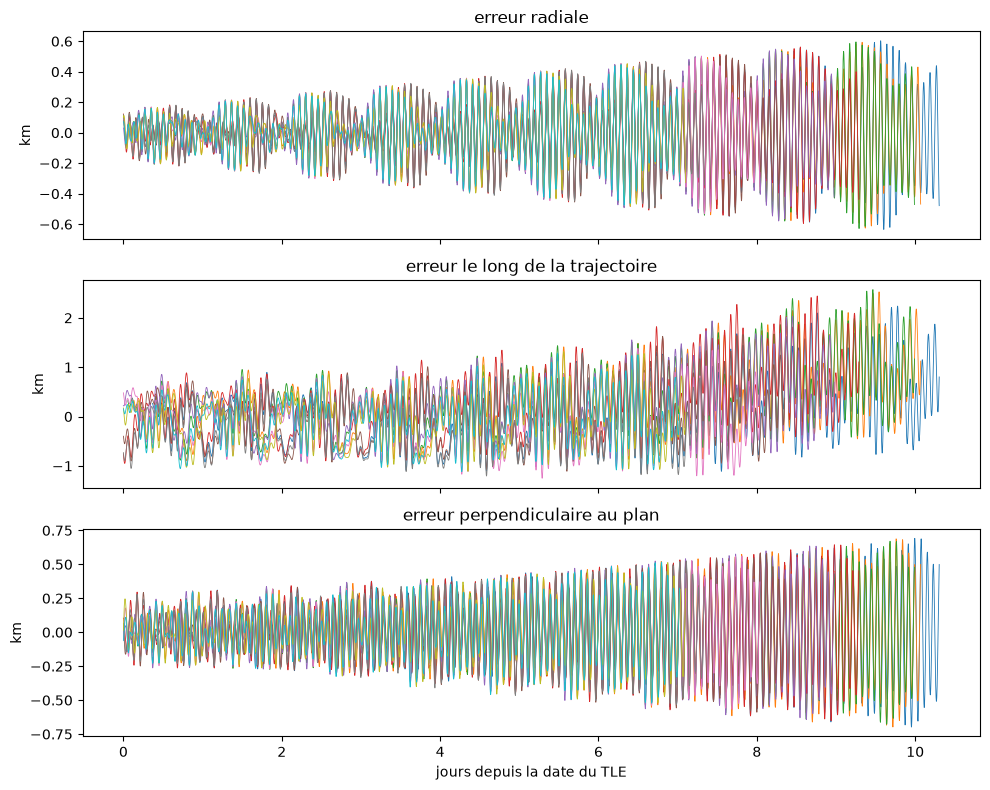

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for sat in satellites:
    days, e_r, e_s, e_w = rsw_error(sat, time, r_true_full)
    for ax, component in zip(axes, (e_r, e_s, e_w)):
        ax.plot(days, component, linewidth=0.6)

for ax, name in zip(axes, ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

En R et en W, les courbes des 10 TLE se superposent presque : même oscillation, même croissance. Au bout de 6 à 7 jours, l'amplitude vaut environ 500 m pour tous les TLE. Cette partie de l'erreur dépend surtout du temps écoulé depuis la date du TLE.

En S, les courbes sont dispersées dès le départ (entre −1 et +0,5 km), et la moyenne dérive différemment selon le TLE : entre 0 et +400 m entre le 6e et le 7e jour, et jusqu'à +1 km à 10 jours pour les premiers TLE. Cette dérive est propre à chaque TLE. C'est la partie la plus difficile à prévoir.

## Étape 5 : première correction

En R et en W, l'erreur a presque la même forme pour tous les TLE. L'idée la plus simple est de prendre la moyenne des erreurs des 10 TLE, en fonction du temps écoulé depuis la date du TLE, et de l'ajouter à SGP4.

Pour savoir si ça marche, il faut tester la correction sur d'autres TLE que ceux qui ont servi à la calculer. Sinon, on mesure seulement à quel point la moyenne ressemble aux données qui l'ont construite. On prend donc le fichier SP3 suivant (du 11 au 21 janvier) et les TLE publiés pendant ses 3 premiers jours.

In [13]:
def read_sp3(path):
    lines = subprocess.run(["gzip", "-dc", path], capture_output=True, text=True, check=True).stdout.splitlines()

    dates, r = [], []
    for line in lines:
        if line.startswith("*"):
            dates.append([float(x) for x in line[1:].split()])
        elif line.startswith("P"):
            r.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])

    dates = np.array(dates)
    year, month, day, hour, minute = dates[:, :5].astype(int).T
    time = Time(
        {"year": year, "month": month, "day": day, "hour": hour, "minute": minute, "second": dates[:, 5]},
        format="ymdhms", scale="tai",
    )
    itrs = ITRS(CartesianRepresentation(np.array(r).T * u.km), obstime=time)
    return time, itrs.transform_to(TEME(obstime=time)).cartesian.xyz.to_value(u.km).T


test_time, test_r_true = read_sp3(Path("data/sp3/s6a/ssas6a30.b24011.e24021.DG_.sp3.001.Z"))

test_satellites, seen = [], set()
for line1, line2 in zip(tle[0::2], tle[1::2]):
    sat = Satrec.twoline2rv(line1, line2)
    date = Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc")
    if date < test_time[0] or line1[18:32] in seen:
        continue
    if date > test_time[0] + 3 * u.day:
        break
    seen.add(line1[18:32])
    test_satellites.append(sat)

print(len(test_satellites), "TLE de test, à partir du", test_time[0].utc.iso)

6 TLE de test, à partir du 2024-01-11 21:16:23.000


Les TLE ne tombent pas tous au même moment par rapport aux dates du SP3. Pour faire la moyenne, on ramène donc chaque courbe sur une même grille : une valeur par minute, de 0 à 7 jours après la date du TLE. C'est `np.interp` qui fait l'interpolation linéaire.

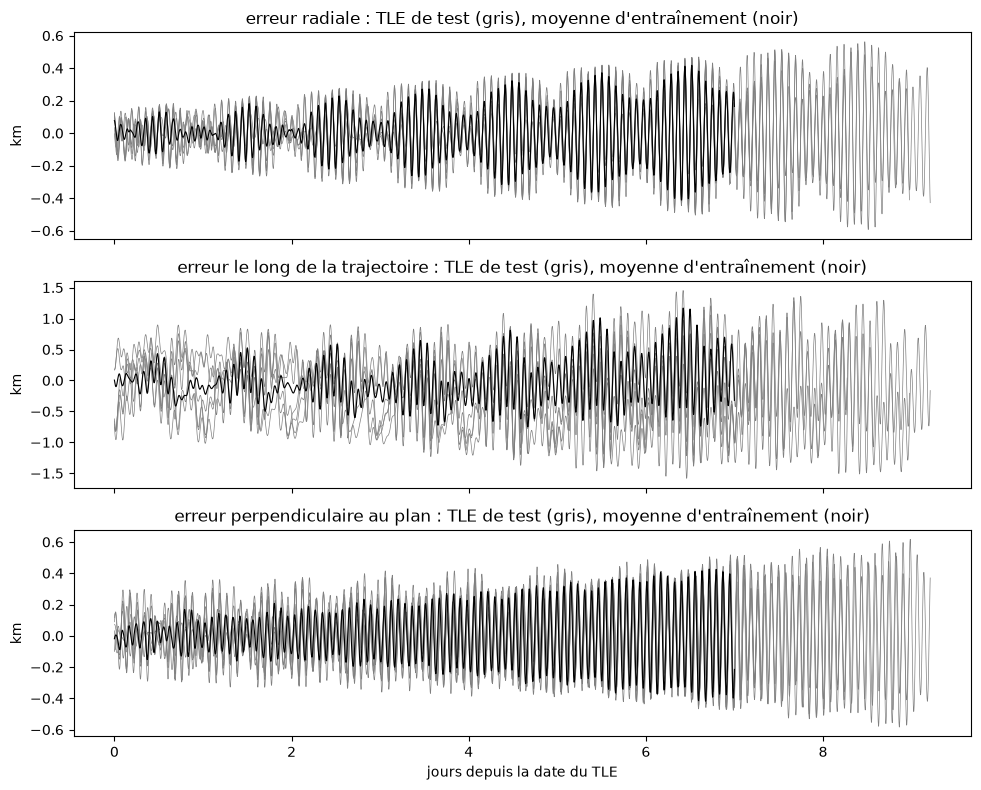

In [14]:
grid = np.arange(0, 7, 1 / 1440)  # en jours, 1440 minutes par jour

curves = []
for sat in satellites:
    days, e_r, e_s, e_w = rsw_error(sat, time, r_true_full)
    curves.append([np.interp(grid, days, component) for component in (e_r, e_s, e_w)])
mean_error = np.mean(curves, axis=0)  # (3, len(grid)) : R, S, W

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for sat in test_satellites:
    days, e_r, e_s, e_w = rsw_error(sat, test_time, test_r_true)
    for ax, component in zip(axes, (e_r, e_s, e_w)):
        ax.plot(days, component, color="gray", linewidth=0.5)
for ax, mean, name in zip(axes, mean_error, ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.plot(grid, mean, color="black", linewidth=0.8)
    ax.set_title(f"erreur {name} : TLE de test (gris), moyenne d'entraînement (noir)")
    ax.set_ylabel("km")
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

La moyenne garde les oscillations : elles sont en phase d'un TLE à l'autre, donc elles ne s'annulent pas.

Pour comparer, on essaie aussi une correction encore plus simple : un polynôme de degré 2 en fonction du temps, ajusté sur la courbe moyenne.

On mesure chaque correction comme Peng & Bai, par la part de l'erreur qui reste, composante par composante :

$$P_{ML} = 100 \cdot \dfrac{\sum |e - \hat e|}{\sum |e|}$$

où $\hat e$ est l'erreur prédite par la correction. 100 % veut dire aucune correction, et 0 % une correction parfaite. À côté, on garde la RMS (racine de la moyenne des carrés) de l'erreur qui reste, pour avoir un ordre de grandeur en km. On calcule les deux sur les 7 premiers jours de chaque TLE de test.

In [15]:
polynomials = [np.polyfit(grid, mean, 2) for mean in mean_error]

residuals = {"sans correction": [], "courbe moyenne": [], "polynôme": []}
for sat in test_satellites:
    days, e_r, e_s, e_w = rsw_error(sat, test_time, test_r_true)
    keep = days < 7
    e = np.array([e_r, e_s, e_w])[:, keep]
    residuals["sans correction"].append(e)
    residuals["courbe moyenne"].append(e - np.array([np.interp(days[keep], grid, mean) for mean in mean_error]))
    residuals["polynôme"].append(e - np.array([np.polyval(p, days[keep]) for p in polynomials]))

def p_ml(e, residual):
    # part de l'erreur qui reste, en %, pour chaque composante (axe 0 : R, S, W)
    axes = tuple(range(1, e.ndim))
    return 100 * np.sum(np.abs(residual), axis=axes) / np.sum(np.abs(e), axis=axes)


e_test = np.concatenate(residuals["sans correction"], axis=1)
for name, residual in residuals.items():
    residual = np.concatenate(residual, axis=1)
    p = p_ml(e_test, residual)
    rms = np.sqrt(np.mean(residual**2, axis=1))
    print(f"{name:16}  P_ML  R {p[0]:5.1f} %   S {p[1]:5.1f} %   W {p[2]:5.1f} %     RMS  R {rms[0]:.3f}   S {rms[1]:.3f}   W {rms[2]:.3f} km")

sans correction   P_ML  R 100.0 %   S 100.0 %   W 100.0 %     RMS  R 0.166   S 0.529   W 0.190 km
courbe moyenne    P_ML  R  49.0 %   S  86.3 %   W  67.8 %     RMS  R 0.077   S 0.455   W 0.133 km
polynôme          P_ML  R 100.0 %   S 100.6 %   W 100.0 %     RMS  R 0.166   S 0.530   W 0.190 km


La courbe moyenne corrige une bonne partie de l'erreur sur des TLE qu'elle n'a jamais vus : il n'en reste que 49 % en R et 68 % en W, mais encore 86 % en S. En S, elle ne peut pas prévoir la dérive, qui change d'un TLE à l'autre.

Le polynôme, lui, ne fait rien : il laisse 100 % de l'erreur. L'erreur est surtout une oscillation à chaque révolution, et un polynôme de degré 2 ne peut pas la suivre : il ne trouve qu'une tendance, et la tendance moyenne est presque nulle.

Il faut rester prudent : on n'a testé que 6 TLE, sur une seule semaine.

## Étape 6 : toute l'année 2024

6 TLE de test, c'est trop peu pour conclure. On refait l'étape 5 sur tous les fichiers SP3 de 2024.

On commence par lire tous les fichiers et les mettre bout à bout. Ils se chevauchent d'environ 30 min. On vérifiera que deux fichiers donnent alors la même position, donc peu importe lequel on garde : on prend le plus récent, et chaque fichier s'arrête là où le suivant commence.

In [16]:
paths = sorted(Path("data/sp3/s6a").glob("*.Z"))
pieces = [read_sp3(path) for path in paths]

overlap = 0
times, positions = [], []
for (file_time, file_r_true), (next_time, next_r_true) in zip(pieces, pieces[1:]):
    keep = file_time < next_time[0]
    overlap = max(overlap, np.abs(file_r_true[~keep] - next_r_true[: (~keep).sum()]).max())
    times.append(file_time[keep])
    positions.append(file_r_true[keep])
times.append(pieces[-1][0])
positions.append(pieces[-1][1])

truth_time = np.concatenate(times)
truth_r = np.concatenate(positions)  # km, TEME
T0 = Time("2024-01-01", scale="utc")
truth_seconds = (truth_time - T0).sec

print(len(truth_time), "états, de", truth_time[0].utc.iso, "à", truth_time[-1].utc.iso)
print("pas de temps :", np.unique(np.round(np.diff(truth_seconds))), "s")
print(f"plus grand écart entre deux fichiers qui se chevauchent : {overlap * 1e3:.4f} m")

528335 états, de 2024-01-01 23:17:23.000 à 2025-01-02 20:51:23.000
pas de temps : [60.] s
plus grand écart entre deux fichiers qui se chevauchent : 0.0016 m


Pas de trou, un état par minute, et deux fichiers qui se chevauchent donnent la même position à 2 mm près.

Cette vérité continue sert d'abord à trouver les manœuvres. Une poussée change le demi-grand axe $a$ de l'orbite. Pour une orbite presque circulaire, la distance moyenne au centre de la Terre sur un nombre entier de révolutions vaut presque $a$ : les oscillations de chaque révolution (étape 1) s'annulent. On compare donc, à chaque instant, la distance moyenne sur les 13 révolutions qui suivent (environ un jour) à celle des 13 qui précèdent. Au-delà de 8 m d'écart, on considère que c'est une manœuvre.

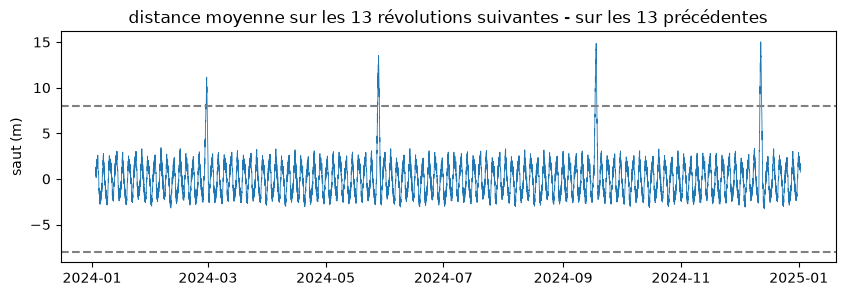

période : 112.4 min
manœuvre vers le 2024-02-29 09:16 UTC
manœuvre vers le 2024-05-28 09:35 UTC
manœuvre vers le 2024-09-18 02:16 UTC
manœuvre vers le 2024-12-12 07:50 UTC


In [17]:
radius = np.linalg.norm(truth_r, axis=1)
period = 2 * np.pi * np.sqrt(radius.mean() ** 3 / 398600.4418)  # s, 3e loi de Kepler
n = int(round(13 * period / 60))  # 13 révolutions, en nombre d'états de 60 s

# somme cumulée : la somme de radius[a:b] vaut sums[b] - sums[a]
sums = np.concatenate([[0], np.cumsum(radius)])
middle = np.arange(n, len(radius) - n)
jump = (sums[middle + n] - 2 * sums[middle] + sums[middle - n]) / n * 1e3  # moyenne après - moyenne avant, en m

above = np.flatnonzero(np.abs(jump) > 8)
groups = np.split(above, np.flatnonzero(np.diff(above) > n) + 1)  # un groupe par manœuvre
burns = Time([truth_time[middle[group[np.argmax(np.abs(jump[group]))]]] for group in groups]).utc

plt.figure(figsize=(10, 3))
plt.plot(truth_time[middle].datetime64, jump, linewidth=0.6)
plt.axhline(8, color="gray", linestyle="--")
plt.axhline(-8, color="gray", linestyle="--")
plt.ylabel("saut (m)")
plt.title("distance moyenne sur les 13 révolutions suivantes - sur les 13 précédentes")
plt.show()

print(f"période : {period / 60:.1f} min")
for burn in burns:
    print("manœuvre vers le", burn.iso[:16], "UTC")

On retrouve 4 manœuvres : fin février, fin mai, mi-septembre et mi-décembre. Ailleurs, le saut reste sous quelques mètres. Comme on compare des moyennes sur un jour, chaque pic est large, et la date de la manœuvre n'est connue qu'à quelques heures près. Par prudence, on prend une marge d'un jour avant chaque manœuvre.

On saute les 4 fichiers qui contiennent une manœuvre : pendant une poussée, SGP4 ne peut pas suivre le satellite. On saute aussi les TLE publiés dans les 5 jours qui suivent une manœuvre. Un TLE est ajusté sur plusieurs jours d'observations, donc juste après une poussée il mélange l'orbite d'avant et celle d'après.

On sépare les données dans le temps, avec une date qu'on gardera jusqu'au bout : l'entraînement avant le 15 octobre, et le test après. Un TLE d'entraînement doit avoir fini sa prédiction avant le 15 octobre, pour que l'entraînement ne voie aucune date du test.

In [18]:
def tles_after(start):
    # les TLE publiés pendant les 3 jours qui suivent start, sans doublons
    satellites, seen = [], set()
    for line1, line2 in zip(tle[0::2], tle[1::2]):
        sat = Satrec.twoline2rv(line1, line2)
        date = Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc")
        if date < start or line1[18:32] in seen:
            continue
        if date > start + 3 * u.day:
            break
        seen.add(line1[18:32])
        satellites.append(sat)
    return satellites


errors, tle_dates = [], []
for path, (file_time, file_r_true) in zip(paths, pieces):
    if any((file_time[0] <= burn) & (burn <= file_time[-1]) for burn in burns):
        print("manœuvre, on saute", path.name)
        continue
    for sat in tles_after(file_time[0]):
        tle_date = Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc")
        if any((burn - 1 * u.day <= tle_date) & (tle_date < burn + 5 * u.day) for burn in burns):
            continue  # juste après une manœuvre
        days, e_r, e_s, e_w = rsw_error(sat, file_time, file_r_true)
        if days[-1] < 7:  # certains fichiers font 9 jours : pas assez de vérité après ce TLE
            continue
        errors.append([np.interp(grid, days, component) for component in (e_r, e_s, e_w)])
        tle_dates.append(tle_date)

errors = np.array(errors)  # (nombre de TLE, 3, len(grid))
tle_dates = Time(tle_dates)
TEST = Time("2024-10-15")
train = tle_dates + 7 * u.day < TEST  # la prédiction se termine avant le test
test = tle_dates >= TEST

print(errors.shape)
print(train.sum(), "TLE d'entraînement,", test.sum(), "TLE de test")

manœuvre, on saute ssas6a30.b24051.e24061.DG_.sp3.001.Z


manœuvre, on saute ssas6a30.b24140.e24150.DG_.sp3.001.Z


manœuvre, on saute ssas6a30.b24259.e24269.DG_.sp3.001.Z


manœuvre, on saute ssas6a30.b24339.e24349.DG_.sp3.001.Z
(185, 3, 10080)
145 TLE d'entraînement, 39 TLE de test


Toutes les erreurs sont maintenant sur la même grille, donc la correction et l'évaluation tiennent en quelques lignes.

sans correction   P_ML  R 100.0 %   S 100.0 %   W 100.0 %     RMS  R 0.160   S 0.510   W 0.256 km
courbe moyenne    P_ML  R  55.2 %   S  83.1 %   W  50.6 %     RMS  R 0.085   S 0.427   W 0.129 km


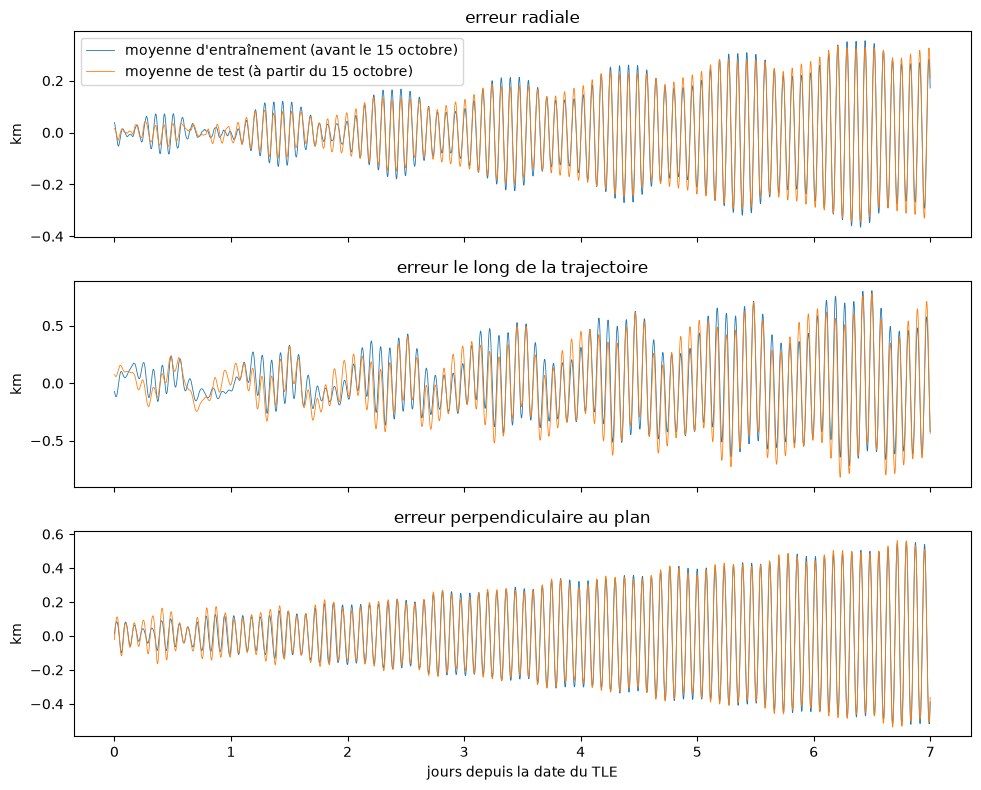

In [19]:
mean_error = errors[train].mean(axis=0)

for name, residual in (("sans correction", errors[test]), ("courbe moyenne", errors[test] - mean_error)):
    p = p_ml(errors[test].transpose(1, 0, 2), residual.transpose(1, 0, 2))  # composante en premier
    rms = np.sqrt(np.mean(residual**2, axis=(0, 2)))
    print(f"{name:16}  P_ML  R {p[0]:5.1f} %   S {p[1]:5.1f} %   W {p[2]:5.1f} %     RMS  R {rms[0]:.3f}   S {rms[1]:.3f}   W {rms[2]:.3f} km")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, k, name in zip(axes, range(3), ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.plot(grid, mean_error[k], linewidth=0.6, label="moyenne d'entraînement (avant le 15 octobre)")
    ax.plot(grid, errors[test].mean(axis=0)[k], linewidth=0.6, label="moyenne de test (à partir du 15 octobre)")
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[0].legend()
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

Le résultat de l'étape 5 tient sur toute l'année : avec la courbe moyenne, il ne reste que 55 % de l'erreur en R et 51 % en W, mais encore 83 % en S.

Les deux moyennes, l'une calculée avant le 15 octobre et l'autre après, se superposent presque, et assez bien en S. La partie systématique de l'erreur ne change donc pas au cours de l'année. Ce qui reste en S, c'est la partie propre à chaque TLE, qui se moyenne à zéro.

Pour voir comment ça varie d'un TLE à l'autre, on calcule l'erreur de chaque TLE séparément. Ici on garde la RMS en km : sans correction, $P_{ML}$ vaudrait 100 % pour tous les TLE, et on ne verrait rien.

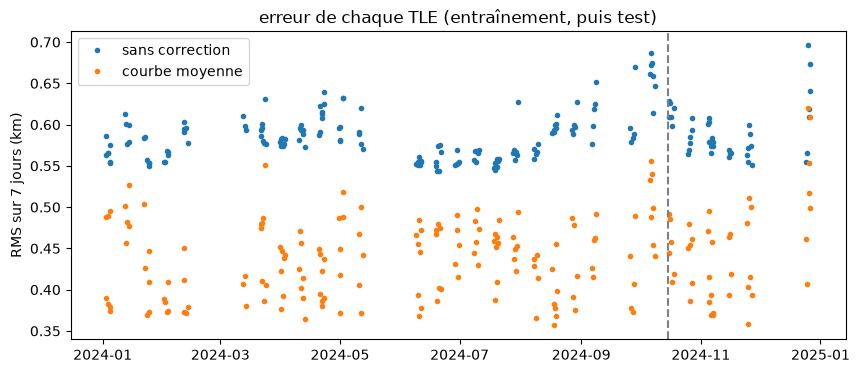

In [20]:
rms_none = np.sqrt(np.mean(np.sum(errors**2, axis=1), axis=1))
rms_mean = np.sqrt(np.mean(np.sum((errors - mean_error) ** 2, axis=1), axis=1))

plt.figure(figsize=(10, 4))
plt.plot(tle_dates.datetime64, rms_none, ".", label="sans correction")
plt.plot(tle_dates.datetime64, rms_mean, ".", label="courbe moyenne")
plt.axvline(TEST.datetime64, color="gray", linestyle="--")
plt.ylabel("RMS sur 7 jours (km)")
plt.title("erreur de chaque TLE (entraînement, puis test)")
plt.legend()
plt.show()

Sans correction, l'erreur est très régulière : entre 550 et 650 m pour 9 TLE sur 10. La correction fait mieux pour chaque TLE, mais pas autant pour tous : les TLE corrigés s'étalent de 360 à 520 m.

## Étape 7 : interpoler la vérité

Jusqu'ici, chaque TLE n'était comparé qu'à la vérité de son propre fichier SP3, ce qui limitait la prédiction à 7 jours. Avec la vérité continue de l'étape 6, on peut aller jusqu'à 14 jours. Mais les dates où l'on voudra l'erreur ne tombent pas sur les minutes rondes du SP3 : il faut savoir évaluer la vérité à n'importe quelle date.

La position varie en douceur d'une minute à l'autre, donc un polynôme qui passe par les états voisins doit suffire. Comme Peng & Bai, on prend l'interpolation de Lagrange sur 10 points : on prend les 10 états les plus proches de la date $t$ voulue et on fait passer par eux un polynôme de degré 9.

$$r(t) = \sum_{k=0}^{9} r_k \prod_{m \neq k} \dfrac{t - t_m}{t_k - t_m}$$

In [21]:
def interpolate(t, x, y, order=10):
    # y aux dates t, à partir des valeurs y aux dates x (triées), avec les `order` points les plus proches
    first = np.clip(np.searchsorted(x, t) - order // 2, 0, len(x) - order)
    window = first[:, None] + np.arange(order)  # (len(t), order) indices des points utilisés
    xs = x[window]

    weights = np.ones_like(xs)
    for k in range(order):
        for m in range(order):
            if m != k:
                weights[:, k] *= (t - xs[:, m]) / (xs[:, k] - xs[:, m])
    return np.einsum("nk,nkj->nj", weights, y[window])  # somme sur k de weights[n, k] * y[window[n, k]]

Pour vérifier, on retire un état sur deux et on essaie de le retrouver à partir des autres. Les points restants sont alors espacés de 2 min au lieu de 1 : si l'interpolation marche dans ce cas, elle marchera encore mieux avec tous les points.

In [22]:
even = np.arange(0, len(truth_seconds), 2)
odd = np.arange(1, len(truth_seconds) - 1, 2)

for order in (4, 6, 8, 10):
    guess = interpolate(truth_seconds[odd], truth_seconds[even], truth_r[even], order)
    gap = np.linalg.norm(guess - truth_r[odd], axis=1) * 1e3
    print(f"{order:2} points : écart médian {np.median(gap):.4f} m, maximum {gap.max():.4f} m")

 4 points : écart médian 28.1771 m, maximum 47.2436 m
 6 points : écart médian 0.0733 m, maximum 0.3210 m


 8 points : écart médian 0.0005 m, maximum 0.0417 m


10 points : écart médian 0.0003 m, maximum 0.0399 m


Avec 10 points, l'interpolation se trompe au pire de quelques centimètres, même avec des points deux fois plus espacés. C'est négligeable devant les centaines de mètres d'erreur de SGP4. Avec 4 points, on serait à plusieurs dizaines de mètres.

## Étape 8 : toute l'orbite, sur 14 jours

On propage maintenant chaque TLE de l'année sur 14 jours, avec une erreur toutes les 10 minutes. Toutes les grilles partent de la date du TLE, donc tous les TLE ont les mêmes $\Delta t$, comme à l'étape 6. Ces dates ne tombent pas sur les minutes rondes du SP3 : c'est là que l'interpolation de l'étape 7 sert.

Pour les manœuvres, on garde les règles de l'étape 6 : pas de TLE publié entre un jour avant et 5 jours après une poussée, et on arrête chaque prédiction un jour avant la poussée suivante. Les dates qui manquent restent à `nan`.

On commence par lire tous les TLE de l'année, sans doublons.

In [23]:
all_satellites, seen = [], set()
for line1, line2 in zip(tle[0::2], tle[1::2]):
    if line1[18:32] in seen:
        continue
    seen.add(line1[18:32])
    all_satellites.append(Satrec.twoline2rv(line1, line2))

all_dates = Time([sat.jdsatepoch for sat in all_satellites], [sat.jdsatepochF for sat in all_satellites], format="jd", scale="utc")

print(len(all_satellites), "TLE")

804 TLE


In [24]:
dt = np.arange(1, 14 * 144 + 1) / 144  # Δt en jours : toutes les 10 min, jusqu'à 14 jours

dataset_e, dataset_dates = [], []
dataset_index = []  # numéro de chaque TLE gardé dans all_satellites
for i, (sat, date) in enumerate(zip(all_satellites, all_dates)):
    if date < truth_time[0] or any((burn - 1 * u.day <= date) & (date < burn + 5 * u.day) for burn in burns):
        continue
    t = date + dt * u.day
    keep = t <= truth_time[-1]
    next_burns = burns[burns > date]
    if len(next_burns):
        keep &= t < next_burns[0] - 1 * u.day  # on s'arrête un jour avant la prochaine poussée
    if not keep.any():
        continue

    r_true_t = interpolate((t[keep] - T0).sec, truth_seconds, truth_r)
    _, e_r, e_s, e_w = rsw_error(sat, t[keep], r_true_t)
    e = np.full((3, len(dt)), np.nan)
    e[:, keep] = e_r, e_s, e_w
    dataset_e.append(e)
    dataset_dates.append(date)
    dataset_index.append(i)

dataset_e = np.array(dataset_e)  # (nombre de TLE, 3, len(dt)) : R, S, W en km
dataset_dates = Time(dataset_dates)
dataset_index = np.array(dataset_index)

print(dataset_e.shape, ":", np.isfinite(dataset_e[:, 0]).sum(), "lignes de données")

(750, 3, 2016) : 1361400 lignes de données


Il y a trop de courbes pour les tracer toutes. Pour chaque $\Delta t$, on trace plutôt la médiane des TLE, et la bande où se trouvent 95 % d'entre eux.

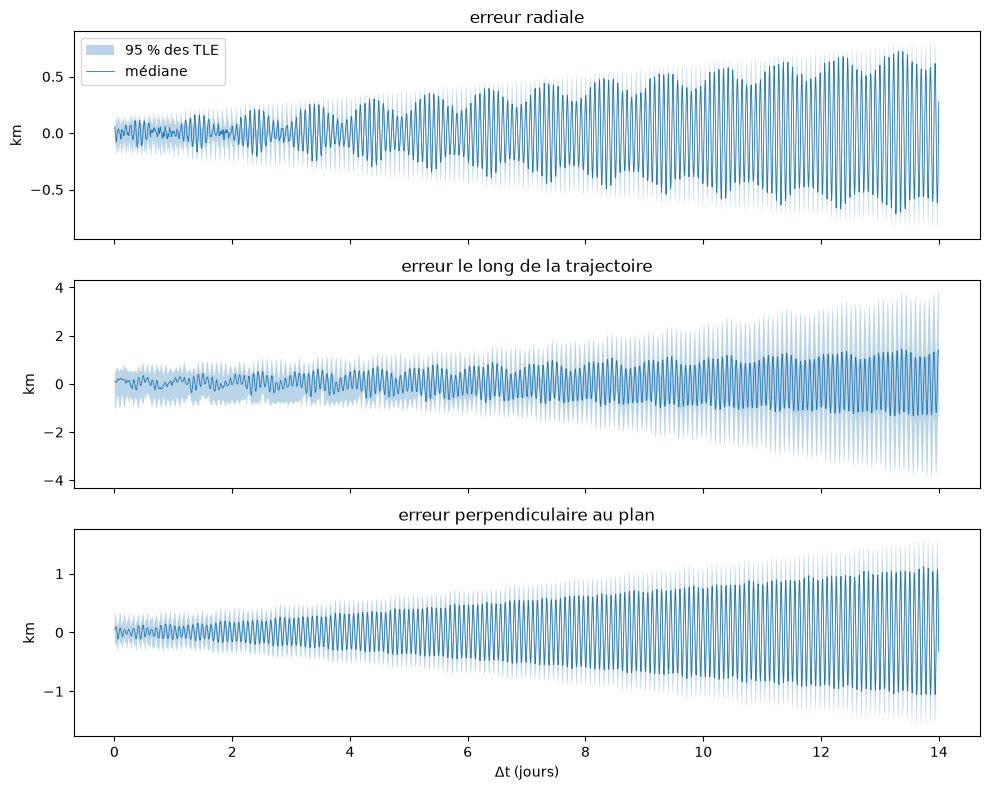

RMS pendant le jour  1 :  R 0.086   S 0.404   W 0.134 km
RMS pendant le jour  7 :  R 0.235   S 0.633   W 0.389 km
RMS pendant le jour 14 :  R 0.460   S 1.536   W 0.776 km


In [25]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, k, name in zip(axes, range(3), ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    low, median, high = np.nanpercentile(dataset_e[:, k], [2.5, 50, 97.5], axis=0)
    ax.fill_between(dt, low, high, alpha=0.3, label="95 % des TLE")
    ax.plot(dt, median, linewidth=0.6, label="médiane")
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[0].legend()
axes[-1].set_xlabel("Δt (jours)")
fig.tight_layout()
plt.show()

for days in (1, 7, 14):
    window = (dt > days - 1) & (dt <= days)  # le jour qui se termine à `days`
    rms = np.sqrt(np.nanmean(dataset_e[:, :, window] ** 2, axis=(0, 2)))
    print(f"RMS pendant le jour {days:2} :  R {rms[0]:.3f}   S {rms[1]:.3f}   W {rms[2]:.3f} km")

La médiane garde les oscillations : elles sont en phase d'un TLE à l'autre, comme à l'étape 5. Regardons où se trouve le satellite à la date de chaque TLE, avec son argument de latitude $u$, l'angle parcouru depuis le nœud ascendant (le passage de l'équateur vers le nord).

In [26]:
u_tle = []
for sat in all_satellites:
    _, r_tle, v_tle = sat.sgp4(sat.jdsatepoch, sat.jdsatepochF)
    h = np.cross(r_tle, v_tle)
    node = np.cross([0, 0, 1], h)  # direction du nœud ascendant
    u_tle.append(np.degrees(np.arctan2(np.dot(np.cross(node, r_tle), h) / np.linalg.norm(h), np.dot(node, r_tle))))

print(f"u à la date des TLE : de {min(u_tle):.4f}° à {max(u_tle):.4f}°")

u à la date des TLE : de -0.0001° à 0.0001°


Tous les TLE sont datés exactement au passage du nœud ascendant. C'est pour ça que les oscillations sont en phase d'un TLE à l'autre depuis l'étape 4 : au même $\Delta t$, tous les satellites sont au même endroit de leur orbite.

Sur 14 jours, la forme de l'étape 6 continue. En R et en W, la médiane suit de près les 95 % des TLE : l'erreur est presque la même pour tous, donc une courbe moyenne en corrigerait l'essentiel. En S, la bande s'élargit beaucoup plus vite que la médiane : la RMS passe de 400 m le premier jour à 630 m le 7e jour, puis à 1,5 km le 14e jour. C'est la dérive propre à chaque TLE, et c'est surtout elle que le réseau devra apprendre.

## Étape 9 : ce que chaque TLE sait de lui-même

Pour corriger la dérive en S, il faut des informations propres à chaque TLE, connues au moment de prédire. Un TLE en a deux sources : ses propres éléments, et son accord avec les TLE qui l'ont précédé.

On commence par les éléments : inclinaison, nœud, excentricité, argument du périgée, anomalie moyenne, moyen mouvement et B* (le coefficient de traînée de SGP4). Ils sont tous pris à la date du TLE, c'est-à-dire au nœud ascendant.

In [27]:
elements = np.array([
    [sat.inclo, sat.nodeo, sat.ecco, sat.argpo, sat.mo, sat.no_kozai, sat.bstar]
    for sat in (all_satellites[i] for i in dataset_index)
])  # (nombre de TLE, 7) : angles en rad, moyen mouvement en rad/min, B* en 1/rayon terrestre

argp, mo = np.degrees(elements[:, 3]), np.degrees(elements[:, 4])
print(f"argument du périgée : de {argp.min():.1f}° à {argp.max():.1f}°")
print(f"anomalie moyenne : de {mo.min():.1f}° à {mo.max():.1f}°")
print(f"périgée + anomalie moyenne : de {(argp + mo).min() - 360:.3f}° à {(argp + mo).max() - 360:.3f}° (modulo 360°)")

argument du périgée : de 269.2° à 271.6°
anomalie moyenne : de 88.4° à 90.9°
périgée + anomalie moyenne : de 0.010° à 0.014° (modulo 360°)


L'argument du périgée ne bouge presque pas : Sentinel-6A est sur une orbite gelée, choisie pour que le périgée et l'excentricité restent fixes. Et comme le TLE est daté au nœud ascendant, l'angle parcouru depuis le nœud vaut 0, donc périgée + anomalie moyenne aussi. L'anomalie moyenne est donc fixée elle aussi.

Ces deux éléments valent presque la même chose pour tous les TLE : ils ne peuvent pas expliquer une erreur qui change d'un TLE à l'autre. On les retire. La position sur l'orbite compte bien pour l'erreur, mais c'est celle à la date $t$ de la prédiction, pas celle à la date du TLE.

Il reste l'inclinaison, le nœud, l'excentricité, le moyen mouvement et B*.

La deuxième source d'information, c'est l'idée de Peng & Bai : l'erreur de cohérence. Au moment de prédire, on ne connaît pas la vérité, mais on peut comparer le TLE à ceux qui l'ont précédé. On propage chacun des 3 TLE précédents jusqu'à la date du nouveau, et on mesure l'écart en RSW en prenant le nouveau comme vérité. Si des TLE successifs ne sont pas d'accord entre eux, c'est peut-être que l'orbite est mal connue.

On laisse la cohérence à `nan` quand une manœuvre tombe entre les deux TLE, avec les mêmes marges qu'avant.

In [28]:
elements = elements[:, [0, 1, 2, 5, 6]]  # inclinaison, nœud, excentricité, moyen mouvement, B*

consistency = np.full((len(dataset_index), 3, 3), np.nan)  # (TLE, k-ième précédent, R S W) en km
gap = np.full((len(dataset_index), 3), np.nan)  # jours entre le k-ième précédent et le TLE
for n, i in enumerate(dataset_index):
    new = all_satellites[i]
    _, r_new, v_new = new.sgp4(new.jdsatepoch, new.jdsatepochF)
    R = np.array(r_new) / np.linalg.norm(r_new)
    W = np.cross(r_new, v_new) / np.linalg.norm(np.cross(r_new, v_new))
    S = np.cross(W, R)
    for k in range(3):
        j = i - 1 - k
        if j < 0:
            break
        gap[n, k] = (all_dates[i] - all_dates[j]).to_value("day")
        if any((all_dates[j] - 5 * u.day <= burn) & (burn < all_dates[i] + 1 * u.day) for burn in burns):
            continue
        _, r_old, _ = all_satellites[j].sgp4(new.jdsatepoch, new.jdsatepochF)
        d = np.array(r_new) - np.array(r_old)
        consistency[n, k] = d @ R, d @ S, d @ W

for k in range(3):
    rms = np.sqrt(np.nanmean(consistency[:, k] ** 2, axis=0)) * 1e3
    print(f"{k + 1}e TLE précédent : {np.nanmedian(gap[:, k]):.2f} jour avant en médiane, "
          f"{np.isnan(consistency[:, k, 0]).sum()} manquants, RMS  R {rms[0]:.0f}  S {rms[1]:.0f}  W {rms[2]:.0f} m")

1e TLE précédent : 0.39 jour avant en médiane, 4 manquants, RMS  R 26  S 30  W 42 m
2e TLE précédent : 0.94 jour avant en médiane, 8 manquants, RMS  R 47  S 44  W 75 m
3e TLE précédent : 1.25 jour avant en médiane, 12 manquants, RMS  R 68  S 57  W 109 m


Les TLE successifs sont très proches : quelques heures à un jour d'écart, et quelques dizaines de mètres de désaccord. Plus le TLE précédent est ancien, plus le désaccord grandit.

Avant de construire un réseau, regardons si ces informations disent quelque chose de la dérive en S. On prend l'erreur moyenne en S pendant le 14e jour, et on la compare à B* et à la cohérence en S avec le 3e TLE précédent.

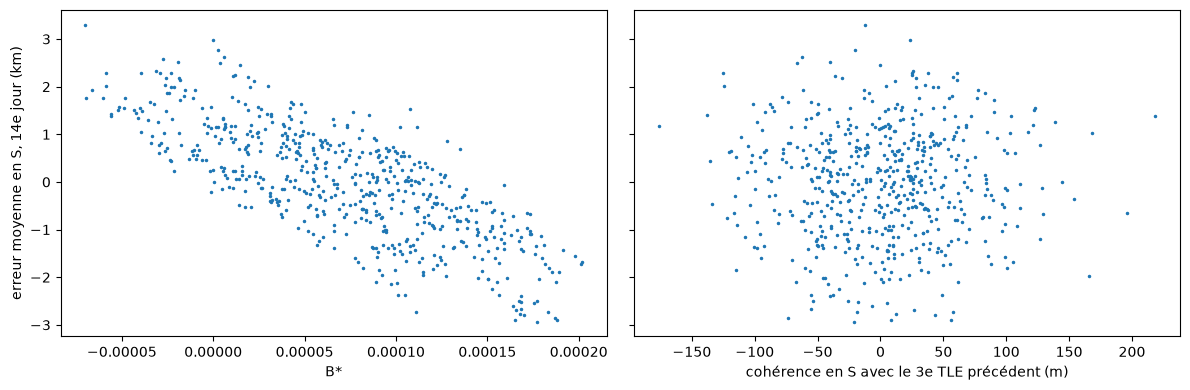

corrélation avec la dérive en S, B*                         : -0.76
corrélation avec la dérive en S, cohérence S, 1er précédent : -0.05
corrélation avec la dérive en S, cohérence S, 2e précédent  : -0.01
corrélation avec la dérive en S, cohérence S, 3e précédent  : +0.01


In [29]:
full = np.isfinite(dataset_e[:, 1, -1])  # TLE dont la prédiction va jusqu'à 14 jours
drift = np.full(len(dataset_e), np.nan)
drift[full] = dataset_e[full, 1][:, dt > 13].mean(axis=1)
bstar = elements[:, 4]

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
left.plot(bstar, drift, ".", markersize=3)
left.set_xlabel("B*")
left.set_ylabel("erreur moyenne en S, 14e jour (km)")
right.plot(consistency[:, 2, 1] * 1e3, drift, ".", markersize=3)
right.set_xlabel("cohérence en S avec le 3e TLE précédent (m)")
fig.tight_layout()
plt.show()

for name, x in (("B*", bstar), ("cohérence S, 1er précédent", consistency[:, 0, 1]),
                ("cohérence S, 2e précédent", consistency[:, 1, 1]), ("cohérence S, 3e précédent", consistency[:, 2, 1])):
    ok = np.isfinite(x) & np.isfinite(drift)
    print(f"corrélation avec la dérive en S, {name:26} : {np.corrcoef(x[ok], drift[ok])[0, 1]:+.2f}")

B* explique une bonne partie de la dérive en S (corrélation de −0,76), et le lien est presque linéaire. Ça se comprend : B* règle la traînée dans SGP4. Un B* trop grand freine trop le satellite. Son orbite descend, il va plus vite, et SGP4 le place en avance : $e = r_{true} - r_{sgp4}$ devient négatif en S. À 1336 km, la vraie traînée est presque nulle, donc B* sert surtout à absorber les erreurs de l'ajustement du TLE. Il est d'ailleurs parfois négatif, ce qui n'a pas de sens physique.

On devine aussi deux bandes parallèles : à B* égal, la dérive peut être décalée d'environ 1 km. Il reste donc autre chose à trouver.

La cohérence en S, elle, n'est pas liée à la dérive (corrélation proche de 0). L'idée de Peng & Bai ne se vérifie donc pas ici, du moins pas seule. On la garde pour l'instant : on verra si le réseau fait mieux avec ou sans.

Enfin, on applique le découpage de l'étape 6 au nouveau jeu de données : un TLE va dans l'entraînement si toute sa prédiction se termine avant le 15 octobre, et dans le test s'il est publié après.

In [30]:
last_dt = np.array([dt[np.isfinite(e[0])].max() for e in dataset_e])  # dernier Δt connu de chaque TLE
last_date = dataset_dates + last_dt * u.day

train_tle = last_date < TEST
test_tle = dataset_dates >= TEST

for name, chosen in (("entraînement", train_tle), ("test", test_tle)):
    rows = np.isfinite(dataset_e[chosen, 0]).sum()
    print(f"{name:12} : {chosen.sum():3} TLE, du {dataset_dates[chosen][0].iso[:10]} au {dataset_dates[chosen][-1].iso[:10]}, {rows} lignes")

entraînement : 557 TLE, du 2024-01-02 au 2024-09-30, 1036467 lignes
test         : 161 TLE, du 2024-10-15 au 2025-01-01, 260421 lignes


## Étape 10 : corrections simples sur 14 jours

Avant de construire un réseau, on regarde ce que font des corrections simples sur les 14 jours. C'est ce que le réseau devra battre.

L'erreur grandit avec $\Delta t$ : sur 14 jours, un seul $P_{ML}$ serait dominé par les derniers jours. On le calcule donc aussi par tranche de $\Delta t$ : 0 à 1 jour, 1 à 2, 2 à 4, 4 à 7 et 7 à 14. On n'utilise que les TLE de test, et on ignore les dates sans vérité (`nan`).

La première correction est la courbe moyenne de l'étape 6, calculée cette fois sur 14 jours.

In [31]:
BINS = [0, 1, 2, 4, 7, 14]  # tranches de Δt, en jours

def show(name, prediction, chosen=test_tle):
    # P_ML des TLE choisis sur 14 jours, puis par tranche de Δt, en ignorant les dates sans vérité
    true = dataset_e[chosen].transpose(1, 0, 2)  # composante en premier
    known = np.isfinite(true)
    e = np.where(known, true, 0)
    residual = np.where(known, true - prediction[chosen].transpose(1, 0, 2), 0)
    columns = [p_ml(e, residual)]
    for low, high in zip(BINS, BINS[1:]):
        window = (dt > low) & (dt <= high)
        columns.append(p_ml(e[..., window], residual[..., window]))
    print(f"{name:16}" + "".join(f" | {p[0]:3.0f} {p[1]:3.0f} {p[2]:3.0f}" for p in columns))

def header():
    print(f"{'P_ML (%)':16}" + f" | {'0-14 j':^11}" + "".join(f" | {f'{low}-{high} j':^11}" for low, high in zip(BINS, BINS[1:])))
    print(f"{'':16}" + " |   R   S   W" * len(BINS))

header()
mean_curve = np.nanmean(dataset_e[train_tle], axis=0)
show("courbe moyenne", np.broadcast_to(mean_curve, dataset_e.shape))

P_ML (%)         |   0-14 j    |    0-1 j    |    1-2 j    |    2-4 j    |    4-7 j    |   7-14 j   
                 |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W


courbe moyenne   |  34  81  39 |  98  98  90 |  91  95  80 |  68  88  61 |  41  76  42 |  23  80  30


La courbe moyenne ne fait presque rien le premier jour, puis de plus en plus. Le premier jour, la partie commune à tous les TLE est petite : sa RMS vaut 33 m en R, pour une erreur de 86 m. L'essentiel de l'erreur vient alors de l'ajustement de chaque TLE, et change d'un TLE à l'autre. La partie commune grandit bien plus vite : entre 7 et 14 jours, elle fait presque toute l'erreur en R et en W. En S, il reste 80 % : c'est la dérive propre à chaque TLE.

L'étape 9 montrait un lien presque linéaire entre B* et cette dérive. On ajoute donc à la courbe un terme proportionnel à B*, avec un coefficient différent pour chaque $\Delta t$ et chaque composante :

$$\hat e(\Delta t) = a(\Delta t) + b(\Delta t) \cdot B^*$$

$a$ et $b$ sont ajustés par moindres carrés sur les TLE d'entraînement. On essaie ensuite la même chose avec tout ce que le TLE sait de lui-même (étape 9) : ses 5 éléments et ses 9 erreurs de cohérence. Ces entrées n'ont pas les mêmes unités, donc on les centre et on les divise par leur écart-type. Une cohérence manquante est remplacée par 0, c'est-à-dire par sa valeur moyenne.

In [32]:
def linear(x):
    # ê(Δt) = a(Δt) + b(Δt)·x, ajusté par moindres carrés pour chaque Δt et chaque composante
    x = (x - np.nanmean(x[train_tle], axis=0)) / np.nanstd(x[train_tle], axis=0)
    A = np.column_stack([np.ones(len(x)), np.nan_to_num(x)])
    prediction = np.empty(dataset_e.shape)
    for k in range(3):
        for j in range(len(dt)):
            ok = train_tle & np.isfinite(dataset_e[:, k, j])
            coefficients, *_ = np.linalg.lstsq(A[ok], dataset_e[ok, k, j])
            prediction[:, k, j] = A @ coefficients
    return prediction

header()
show("B*", linear(elements[:, [4]]))
show("tout", linear(np.column_stack([elements, consistency.reshape(len(consistency), -1)])))

P_ML (%)         |   0-14 j    |    0-1 j    |    1-2 j    |    2-4 j    |    4-7 j    |   7-14 j   
                 |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W


B*               |  34  68  39 |  98  98  89 |  91  95  78 |  68  88  60 |  41  75  43 |  23  59  30


tout             |  35  66  38 | 100  99  88 |  92  96  78 |  69  88  60 |  42  74  42 |  23  56  30


B* ne change que la composante S, et seulement au-delà de 7 jours, où il ne reste plus que 59 % de l'erreur au lieu de 80 %. C'est logique : la dérive vient d'une erreur sur la vitesse moyenne, qui s'accumule à chaque révolution, donc elle ne devient grande qu'au bout de quelques jours.

Avec tout ce que le TLE sait de lui-même, on ne gagne presque rien de plus. Et sur les 4 premiers jours, aucune correction ne fait mieux que la courbe moyenne : la partie de l'erreur propre à chaque TLE n'est pas une combinaison linéaire de ces entrées. Si elle dépend d'elles, c'est d'une manière plus compliquée. C'est ce qu'on va demander à un réseau de neurones.

## Étape 11 : un réseau de neurones

Peng & Bai donnent à un petit réseau de neurones tout ce qu'on sait au moment de prédire. Pour chaque TLE et chaque $\Delta t$, on lui donne :

- $\Delta t$
- les 14 nombres de l'étape 9 : 5 éléments et 9 erreurs de cohérence
- la position et la vitesse SGP4 à la date $t$, en TEME. C'est par elles que le réseau sait où est le satellite sur son orbite, donc à quel moment de l'oscillation

Comme eux, on entraîne un réseau par composante, avec une seule couche de 20 neurones. Chaque neurone applique la fonction logistique $\dfrac{1}{1 + e^{-x}}$, qui ne varie vraiment qu'autour de 0 : on ramène donc chaque entrée entre −1 et 1. Une cohérence manquante vaut 0, le milieu.

Deux lignes à 10 minutes d'écart sont presque identiques. Pour aller plus vite, on n'entraîne que sur une ligne par heure, avec 50 passages sur les données.

In [33]:
states = np.empty((len(dataset_index), len(dt), 6))  # position (km) et vitesse (km/s) SGP4, en TEME
for n, i in enumerate(dataset_index):
    sat = all_satellites[i]
    _, r, v = sat.sgp4_array(np.full(len(dt), sat.jdsatepoch), sat.jdsatepochF + dt)
    states[n] = np.hstack([r, v])

tle_inputs = np.column_stack([elements, consistency.reshape(len(consistency), -1)])  # 14 nombres par TLE
inputs = np.concatenate([
    np.broadcast_to(dt[None, :, None], (len(dataset_index), len(dt), 1)),
    np.broadcast_to(tle_inputs[:, None, :], (len(dataset_index), len(dt), tle_inputs.shape[1])),
    states,
], axis=2)  # (TLE, Δt, 21)
has_truth = np.isfinite(dataset_e[:, 0])  # (TLE, Δt)
hourly = np.arange(len(dt)) % 6 == 5  # Δt = 1 h, 2 h, ...
rows = train_tle[:, None] & has_truth & hourly
print(rows.sum(), "lignes d'entraînement,", inputs.shape[2], "entrées")

scaler = MinMaxScaler((-1, 1)).fit(inputs[rows])
x_train = np.nan_to_num(scaler.transform(inputs[rows]))
x_all = np.nan_to_num(scaler.transform(inputs[has_truth]))

network_prediction = np.full(dataset_e.shape, np.nan)
for k in range(3):
    network = MLPRegressor(hidden_layer_sizes=(20,), activation="logistic", max_iter=50, tol=0, random_state=0)
    with warnings.catch_warnings(category=ConvergenceWarning, action="ignore"):  # on s'arrête exprès après 50 passages
        network.fit(x_train, dataset_e[:, k][rows])
    network_prediction[:, k][has_truth] = network.predict(x_all)

header()
show("B*", linear(elements[:, [4]]))
show("réseau", network_prediction)

172708 lignes d'entraînement, 21 entrées


P_ML (%)         |   0-14 j    |    0-1 j    |    1-2 j    |    2-4 j    |    4-7 j    |   7-14 j   
                 |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W


B*               |  34  68  39 |  98  98  89 |  91  95  78 |  68  88  60 |  41  75  43 |  23  59  30
réseau           |  36  83  36 | 100 120  97 |  92 117  85 |  70 114  64 |  43 106  42 |  25  68  26


Le réseau fait un peu mieux que les corrections linéaires en W, mais nettement moins bien en S. Les 4 premiers jours, il laisse même plus de 100 % de l'erreur : il en ajoute.

Regardons ce qu'il donne sur les TLE qui ont servi à l'entraîner.

In [34]:
header()
show("B*", linear(elements[:, [4]]), train_tle)
show("réseau", network_prediction, train_tle)

P_ML (%)         |   0-14 j    |    0-1 j    |    1-2 j    |    2-4 j    |    4-7 j    |   7-14 j   
                 |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W


B*               |  31  65  38 |  89  95  87 |  83  92  73 |  63  85  53 |  39  72  39 |  22  58  33
réseau           |  34  55  27 | 100 100  90 |  93  96  73 |  70  89  51 |  43  73  33 |  23  40  19


Sur l'entraînement, il ne reste que 55 % de l'erreur en S, contre 83 % sur le test : le réseau a appris les TLE d'entraînement par cœur, au lieu d'une règle qui marche sur d'autres TLE. La correction B*, elle, donne presque le même résultat sur les deux (65 % et 68 %).

Ça se comprend. La dérive en S est un seul nombre par TLE, qui ne dépend que de ce que le TLE sait de lui-même. Pour l'apprendre, on n'a donc pas 172 708 exemples, mais 557 : un par TLE. Avec 14 nombres par TLE, chaque TLE est reconnaissable à ses entrées, et le réseau peut retenir la dérive de chacun.

En R, le réseau ne fait pas mieux que la courbe moyenne. C'est peut-être la phase : il ne la voit qu'à travers la position et la vitesse en TEME, et il doit la retrouver seul.

## Étape 12 : le surapprentissage

Au fil des passages, le réseau apprend d'abord ce qui est commun aux TLE, puis il retient chaque TLE d'entraînement. Il faudrait l'arrêter entre les deux. Mais pour savoir quand, il faut des TLE qui ne servent pas à l'entraînement, et on ne peut pas utiliser ceux du test : on choisirait le réglage qui marche le mieux sur le test, et le test ne mesurerait plus rien.

On met donc de côté une troisième partie, la validation : les TLE publiés après le 1er septembre dont la prédiction se termine avant le 15 octobre. L'entraînement s'arrête au 1er septembre. Après chaque passage, on mesure l'erreur du réseau sur la validation, et on garde le réseau du meilleur passage.

On essaie deux jeux d'entrées. Le premier est celui de l'étape 11. Dans le second, le TLE n'est plus décrit que par B*. Avec 14 nombres par TLE, chaque TLE est reconnaissable ; avec B* seul, beaucoup moins. Et l'étape 10 montre que les autres entrées n'apportaient presque rien.

477 TLE d'entraînement, 50 TLE de validation


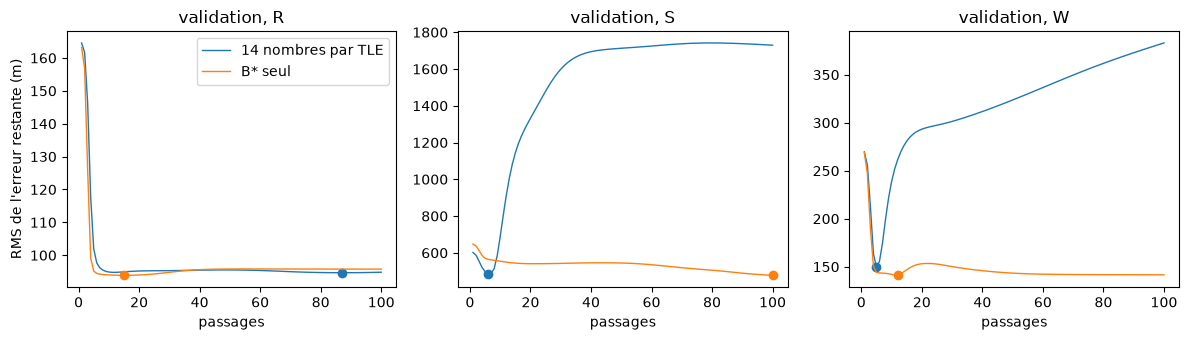

P_ML (%)         |   0-14 j    |    0-1 j    |    1-2 j    |    2-4 j    |    4-7 j    |   7-14 j   
                 |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W |   R   S   W
réseau, étape 11 |  36  83  36 | 100 120  97 |  92 117  85 |  70 114  64 |  43 106  42 |  25  68  26
14 nombres       |  38  70  37 | 101 100 110 |  94  95  92 |  71  90  65 |  44  80  41 |  26  60  26
B* seul          |  36  67  35 | 102 103 100 |  93  99  84 |  70  92  60 |  43  78  39 |  24  55  25


In [35]:
VALIDATION = Time("2024-09-01")
fit_tle = last_date < VALIDATION  # entraînement, sans la validation
validation_tle = (dataset_dates >= VALIDATION) & (last_date < TEST)
print(fit_tle.sum(), "TLE d'entraînement,", validation_tle.sum(), "TLE de validation")

def train_networks(tle_inputs, passes=100):
    # un réseau par composante, gardé au passage où il se trompe le moins sur la validation
    inputs = np.concatenate([
        np.broadcast_to(dt[None, :, None], (len(dataset_index), len(dt), 1)),
        np.broadcast_to(tle_inputs[:, None, :], (len(dataset_index), len(dt), tle_inputs.shape[1])),
        states,
    ], axis=2)
    rows = fit_tle[:, None] & has_truth & hourly
    check = validation_tle[:, None] & has_truth
    scaler = MinMaxScaler((-1, 1)).fit(inputs[rows])
    x_train = np.nan_to_num(scaler.transform(inputs[rows]))
    x_check = np.nan_to_num(scaler.transform(inputs[check]))
    x_all = np.nan_to_num(scaler.transform(inputs[has_truth]))

    prediction = np.full(dataset_e.shape, np.nan)
    curves = np.empty((3, passes))  # RMS sur la validation après chaque passage, en km
    for k in range(3):
        network = MLPRegressor(hidden_layer_sizes=(20,), activation="logistic", random_state=0)
        for n in range(passes):
            network.partial_fit(x_train, dataset_e[:, k][rows])
            curves[k, n] = np.sqrt(np.mean((network.predict(x_check) - dataset_e[:, k][check]) ** 2))
            if curves[k, n] == curves[k, : n + 1].min():
                best = copy.deepcopy(network)
        prediction[:, k][has_truth] = best.predict(x_all)
    return prediction, curves

all_prediction, all_curves = train_networks(tle_inputs)
bstar_prediction, bstar_curves = train_networks(elements[:, [4]])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, k, name in zip(axes, range(3), "RSW"):
    for curves, label in ((all_curves, "14 nombres par TLE"), (bstar_curves, "B* seul")):
        line, = ax.plot(np.arange(1, curves.shape[1] + 1), curves[k] * 1e3, linewidth=1, label=label)
        best = np.argmin(curves[k])
        ax.plot(best + 1, curves[k, best] * 1e3, "o", color=line.get_color())
    ax.set_title(f"validation, {name}")
    ax.set_xlabel("passages")
axes[0].set_ylabel("RMS de l'erreur restante (m)")
axes[0].legend()
fig.tight_layout()
plt.show()

header()
show("réseau, étape 11", network_prediction)
show("14 nombres", all_prediction)
show("B* seul", bstar_prediction)

Avec les 14 nombres, l'erreur en S sur la validation est la plus basse après 6 passages, puis elle remonte jusqu'à 1,7 km : le réseau apprend les TLE d'entraînement par cœur, et ce qu'il retient est faux pour les autres. Arrêté au bon moment, il ne laisse plus que 70 % de l'erreur en S sur le test, au lieu de 83 %.

Avec B* seul, la courbe ne remonte pas : l'erreur sur la validation descend encore, lentement, au 100e passage. Le réseau a moins de prise pour reconnaître chaque TLE. C'est aussi le meilleur des deux sur le test, dans les trois composantes.

Mais il ne fait guère mieux que la correction linéaire de l'étape 10 : 67 % en S au lieu de 68 %, 35 % en W au lieu de 39 %. Et le premier jour, aucun réseau ne corrige rien. Le réseau n'invente pas d'information : avec ces entrées, il ne trouve presque rien de plus que B*. Pour aller plus loin, il faudra lui donner autre chose, par exemple ce qui sépare les deux bandes de l'étape 9.